# Titanic: End-to-End Machine Learning + ANN Project

# Titanic Dataset — Column Meanings

- **PassengerId:** Unique ID of each passenger.
- **Survived:** 0 = Did not survive, 1 = Survived.
- **Pclass:** Ticket class (1st, 2nd, or 3rd).
- **Name:** Full name of the passenger.
- **Sex:** Passenger's recorded sex (male/female).
- **Age:** Passenger's age in years.
- **SibSp:** Number of siblings and spouse aboard.
- **Parch:** Number of parents and children aboard.
- **Ticket:** Passenger's ticket number.
- **Fare:** Ticket price paid.
- **Cabin:** Passenger's cabin number.
- **Embarked:** Port where passenger boarded (C = Cherbourg, Q = Queenstown, S = Southampton).

**Note:** `Survived` is the target column. `PassengerId` is an identifier. We use EDA to understand the data, find missing values, and explore relationships between features and survival.

## 1. Install / import libraries

If a package is missing, uncomment the install line and run it, then restart the kernel if prompted.

In [1]:
# If needed, run this in a notebook cell:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import warnings
warnings.filterwarnings("ignore")

import os
import re
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", __import__("sklearn").__version__)

Python: 3.14.6
pandas: 3.0.3
scikit-learn: 1.9.0


## 2. Load the Titanic dataset

In [2]:
import pandas as pd

df = pd.read_csv("train.csv")

print(df.shape)
display(df.head())

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Basic data inspection

In [3]:
print("Rows, columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Rows, columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Missing values:


,missing_count
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0



Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292



Categorical summary:


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


## 4. Basic EDA: target and feature distributions

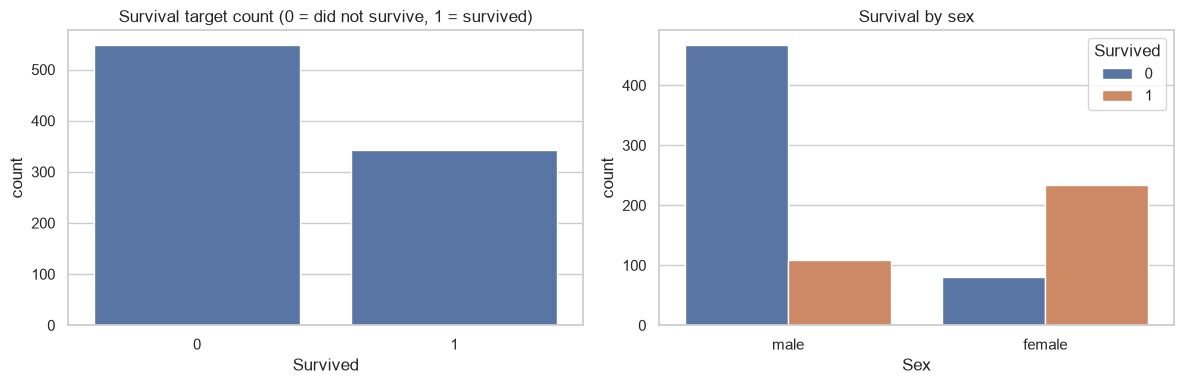

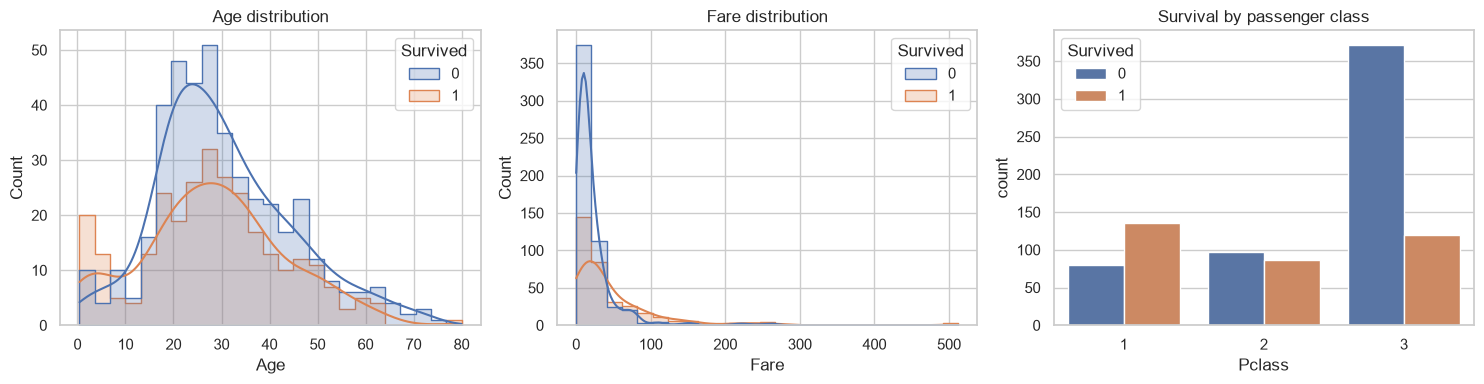

In [4]:


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Survived", ax=axes[0])
axes[0].set_title("Survival target count (0 = did not survive, 1 = survived)")
sns.countplot(data=df, x="Sex", hue="Survived", ax=axes[1])
axes[1].set_title("Survival by sex")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, kde=True, ax=axes[0], element="step")
sns.histplot(data=df, x="Fare", hue="Survived", bins=25, kde=True, ax=axes[1], element="step")
sns.countplot(data=df, x="Pclass", hue="Survived", ax=axes[2])
axes[0].set_title("Age distribution")
axes[1].set_title("Fare distribution")
axes[2].set_title("Survival by passenger class")
plt.tight_layout()
plt.show()

## 5. EDA: correlation and categorical comparisons

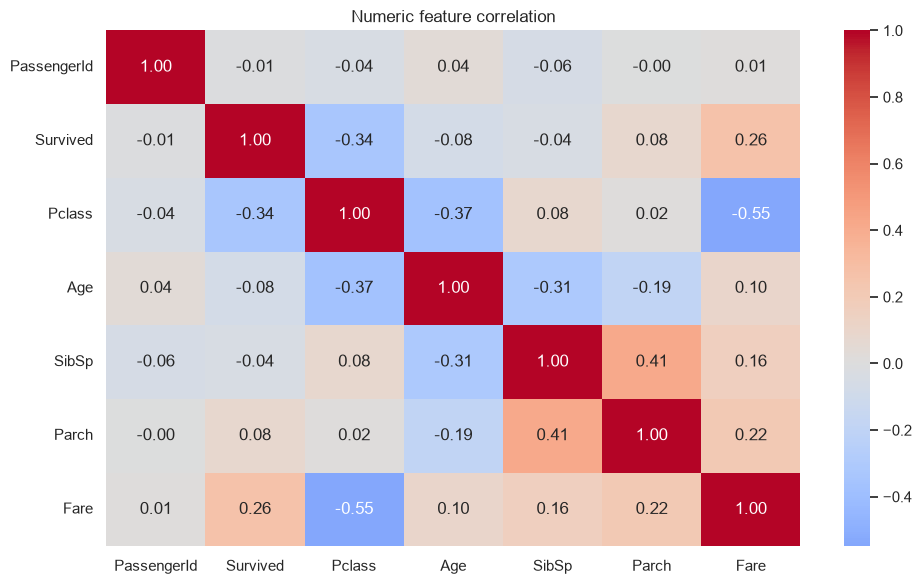

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric feature correlation")
plt.tight_layout()
plt.show()

## 6. Feature engineering

In [6]:

def add_features(data):
    data = data.copy()

    # 1. Extract Title from Name
    data["Title"] = data["Name"].str.extract(r",\s*([^.]+)\.")

    # 2. Calculate Family Size
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1

    # 3. Check whether passenger is alone
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    # Drop unnecessary columns
    data = data.drop(columns=["Name", "Ticket", "Cabin"])

    return data


featured_df = add_features(df)

display(featured_df.head())
print("Shape:", featured_df.shape)


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone
0,1,0,3,male,22.0,1,0,7.2500,S,Mr,2,0
1,2,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0
2,3,1,3,female,26.0,0,0,7.9250,S,Miss,1,1
3,4,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0
4,5,0,3,male,35.0,0,0,8.0500,S,Mr,1,1


Shape: (891, 12)


## 7. Prepare X and y; split before fitting preprocessing

In [7]:
X = featured_df.drop(columns=["Survived", "PassengerId"], errors="ignore")
y = featured_df["Survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Train target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

X_train: (712, 10)
X_test : (179, 10)
Train target distribution:


,proportion
Survived,
0,0.616573
1,0.383427


## 8. Build a preprocessing + model pipeline

The pipeline imputes missing numeric values with the median, imputes missing categorical values with the most frequent value, and one-hot encodes categorical columns. The preprocessing is fitted only on the training split, which helps prevent data leakage.

In [8]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

# Compatibility with both newer and older scikit-learn releases.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=True)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot)
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
    ))
])

baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print(classification_report(y_test, baseline_pred, zero_division=0))

Baseline accuracy: 0.7989
              precision    recall  f1-score   support

           0       0.85      0.82      0.83       110
           1       0.73      0.77      0.75        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



## 9. Hyperparameter tuning with GridSearchCV

In [9]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best parameters:")
print(grid_search.best_params_)
print("Best mean CV F1:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best mean CV F1: 0.7651


## 10. Final evaluation on the held-out test split

,Score
Accuracy,0.815642
Precision,0.743243
Recall,0.797101
F1-score,0.769231


                 precision    recall  f1-score   support

Did not survive       0.87      0.83      0.85       110
       Survived       0.74      0.80      0.77        69

       accuracy                           0.82       179
      macro avg       0.80      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



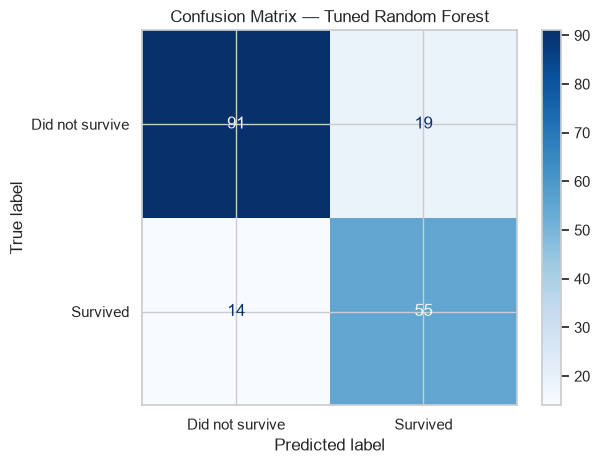

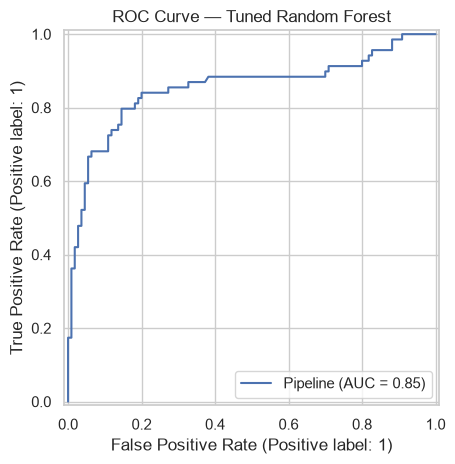

In [10]:
y_pred = best_model.predict(X_test)

results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
}
display(pd.DataFrame(results, index=["Test score"]).T.rename(columns={"Test score": "Score"}))

print(classification_report(y_test, y_pred, target_names=["Did not survive", "Survived"], zero_division=0))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, display_labels=["Did not survive", "Survived"], cmap="Blues"
)
plt.title("Confusion Matrix — Tuned Random Forest")
plt.tight_layout()
plt.show()

if hasattr(best_model, "predict_proba"):
    RocCurveDisplay.from_estimator(best_model, X_test, y_test)
    plt.title("ROC Curve — Tuned Random Forest")
    plt.tight_layout()
    plt.show()

## 12. Save the trained model

In [11]:
model_path = "titanic_model.joblib"
joblib.dump(best_model, model_path)
print("Saved model to:", os.path.abspath(model_path))

Saved model to: c:\Users\mdsal\OneDrive\Desktop\MI HUB\titanic_model.joblib


In [12]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


## 14. Deep Learning: ANN with Keras (optional)

This section is optional because TensorFlow can take time to install. Run it only after the classical ML pipeline works. If TensorFlow is not installed, use `%pip install tensorflow` in a separate cell and restart the kernel.

For ANN, we create a **dense numeric matrix** using imputation, one-hot encoding, and scaling. Fit preprocessing only on the training split. A neural network does not automatically outperform Random Forest on small tabular datasets; compare test metrics fairly.

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.4130 - loss: 0.7458 - val_accuracy: 0.4406 - val_loss: 0.7029
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5149 - loss: 0.6885 - val_accuracy: 0.4895 - val_loss: 0.6623
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7030 - loss: 0.6507 - val_accuracy: 0.6993 - val_loss: 0.6299
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7610 - loss: 0.6188 - val_accuracy: 0.7413 - val_loss: 0.5969
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7768 - loss: 0.5781 - val_accuracy: 0.7902 - val_loss: 0.5582
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7996 - loss: 0.5348 - val_accuracy: 0.8112 - val_loss: 0.5244
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8207 - loss: 0.4973 - val_accuracy: 0.7902 - val_loss: 0.4982
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8207 - loss: 0.4670 - val_accuracy: 0.7832 - val_los

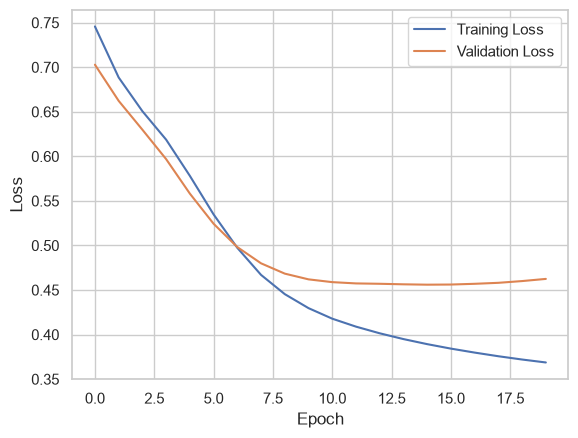

In [13]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# 1. Prepare the data
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Convert data to dense arrays for ANN
X_train = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_test = X_test.toarray() if hasattr(X_test, "toarray") else X_test

# 2. Build the ANN model
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# 3. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 4. Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

# 5. Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", round(accuracy, 4))

# 6. Make predictions
probabilities = model.predict(X_test)
predictions = (probabilities >= 0.5).astype(int)

print(classification_report(y_test, predictions))

# 7. Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# 8. Save the model
model.save("titanic_ann.keras")


## 15. What to explain during the session

- **Problem definition:** predict the target `Survived` from passenger attributes.
- **Data collection:** download `train.csv` from Kaggle and inspect the data dictionary.
- **EDA:** check size, dtypes, missing values, class balance, and a few feature relationships.
- **Feature engineering:** derive title, family size, travelling alone, deck, and ticket prefix.
- **Preprocessing:** impute missing values and encode categorical features inside a pipeline.
- **Training:** train a baseline Random Forest.
- **Tuning:** use cross-validation on training data to select hyperparameters.
- **Evaluation:** use a held-out test split and report multiple metrics, not accuracy alone.
- **Deployment:** save the complete sklearn pipeline and load it inside a small Streamlit app.
- **Deep Learning:** train a small ANN and compare its results cautiously with the ML model.

### Important limitation
Kaggle's competition `test.csv` does not include labels, so you cannot calculate accuracy on that file. Use a held-out split from `train.csv` for evaluation. Once satisfied, the trained model can generate predictions for Kaggle `test.csv` if you want to create a submission.

In [14]:
accuracy

0.8212290406227112